[Sommaire](00_sommaire.ipynb) · ⬅ [Thème 7 — Maths et gloutons](theme7_maths_gloutons.ipynb)

# Thème 8 — Programmation dynamique et backtracking

**Dans ce notebook, tu vas apprendre :**
- reconnaître un problème qui se découpe en **sous-problèmes** qui reviennent sans cesse ;
- retenir ces résultats pour passer d'un temps exponentiel à un temps linéaire : la **programmation dynamique** ;
- remplir un tableau case par case, avec une méthode en 4 questions ;
- générer **toutes** les solutions en essayant, puis en revenant en arrière : le **backtracking**.

**Prérequis :** thèmes 0, 2 et 5 (notation O, grilles, récursivité), et le glouton du thème 7

> Exécute d'abord la cellule ci-dessous : elle contient l'outil `verifier`, qui teste automatiquement ta solution dans l'exercice final.

In [ ]:
# Outil utilisé dans l'exercice « À toi de jouer » de ce notebook.
# Il appelle ta fonction sur plusieurs cas et affiche ✅ (bon), ❌ (mauvais) ou 💥 (plantage).
# Tu n'as pas besoin de comprendre ce code pour t'en servir : exécute simplement cette cellule.

import copy

def verifier(fonction, cas):
    reussis = 0
    for arguments, attendu in cas:
        texte_args = ", ".join(repr(a) for a in arguments)
        try:
            obtenu = fonction(*copy.deepcopy(arguments))
        except Exception as erreur:
            print(f"💥 {fonction.__name__}({texte_args}) a planté : {type(erreur).__name__}: {erreur}")
            continue
        if obtenu == attendu:
            reussis += 1
            print(f"✅ {fonction.__name__}({texte_args}) -> {obtenu!r}")
        else:
            print(f"❌ {fonction.__name__}({texte_args}) -> {obtenu!r}   (attendu : {attendu!r})")
    print(f"\n{reussis}/{len(cas)} tests réussis")

## Partie 1 — La programmation dynamique

### Le problème de départ
> Un escalier a `n` marches. À chaque pas, tu montes **1 ou 2** marches. De combien de façons différentes peux-tu arriver en haut ?
> `n = 4` → **5** façons : 1+1+1+1, 1+1+2, 1+2+1, 2+1+1, 2+2.

Lister toutes les façons devient vite impossible : pour `n = 40`, il y en a plus de 165 millions.

### L'idée clé : regarder le dernier pas
Pour arriver sur la marche `n`, le **dernier pas** vient forcément :
- de la marche `n − 1` (un pas d'une marche),
- ou de la marche `n − 2` (un pas de deux marches).

Le nombre de façons d'arriver en `n` est donc la somme des façons d'arriver en `n − 1` et des façons d'arriver en `n − 2` :

**`façons(n) = façons(n − 1) + façons(n − 2)`**, avec `façons(0) = 1` (rester en bas : une seule façon, ne rien faire) et `façons(1) = 1`.

Un gros problème s'exprime avec des **versions plus petites du même problème** : c'est exactement ce que sait faire une fonction récursive (thème 5).

### Version 1 : la récursion directe — juste, mais catastrophique

In [ ]:
appels = 0                                  # pour compter le travail effectué

def facons_recursif(n):
    global appels                           # global : la fonction modifie la variable appels définie dehors
    appels += 1
    if n <= 1:
        return 1                            # marche 0 ou 1 : une seule façon
    return facons_recursif(n - 1) + facons_recursif(n - 2)

for n in [10, 20, 30]:
    appels = 0
    resultat = facons_recursif(n)
    print(f"n = {n} : {resultat} façons, calculées en {appels} appels")

Le nombre d'appels **explose** : il est multiplié par environ 1,6 à chaque marche supplémentaire. C'est un temps **exponentiel** (on l'écrit souvent O(2ⁿ)) : pour `n = 50`, il faudrait déjà plus de 40 milliards d'appels.

Pourquoi ? Parce que la fonction **recalcule sans cesse les mêmes choses**. Pour `façons(5)`, elle calcule `façons(3)` deux fois, `façons(2)` trois fois…

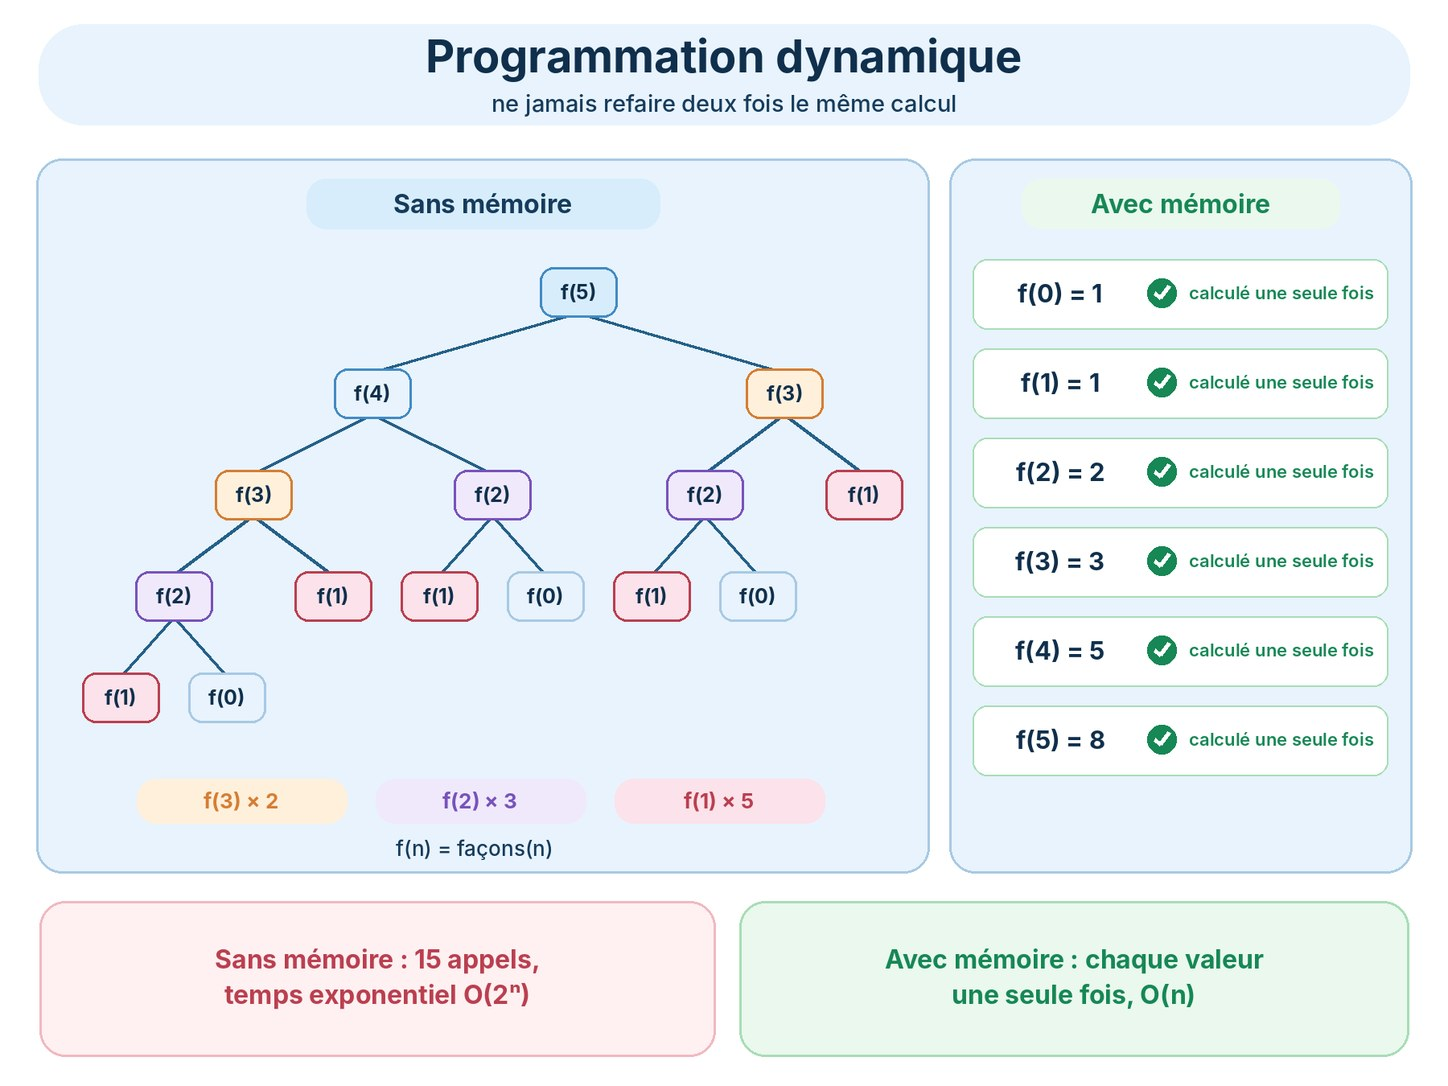

Sur l'image, à gauche, l'arbre des appels de `façons(5)` : chaque appel en lance deux autres. Les cases de même couleur sont **le même calcul refait** : `façons(3)` apparaît 2 fois, `façons(2)` 3 fois, `façons(1)` 5 fois. À droite, avec une mémoire : chaque valeur, de `façons(0)` à `façons(5)`, n'est calculée **qu'une seule fois**, puis simplement relue. En bas : sans mémoire, un temps exponentiel ; avec mémoire, O(n).

### Version 2 : se souvenir (la mémoïsation)
Image mentale : un **carnet**. La première fois qu'on calcule `façons(3)`, on note le résultat dans le carnet ; les fois suivantes, on se contente de le relire. Le carnet, c'est un dict (thème 1) : `k → résultat`.

In [ ]:
def facons_memo(n):
    carnet = {}                              # k -> nombre de façons d'arriver sur la marche k

    def f(k):
        if k <= 1:
            return 1
        if k not in carnet:                  # jamais calculé : on le calcule UNE fois…
            carnet[k] = f(k - 1) + f(k - 2)
        return carnet[k]                     # … et toutes les fois suivantes, on relit le carnet

    return f(n)

print(facons_memo(30))     # 1346269, instantanément
print(facons_memo(90))     # 4660046610375530309

Python sait aussi le faire tout seul : le **décorateur** `@cache` (module `functools`), placé juste au-dessus d'une fonction, lui ajoute automatiquement ce carnet.

In [ ]:
from functools import cache

@cache                         # Python retient chaque résultat déjà calculé
def facons(n):
    if n <= 1:
        return 1
    return facons(n - 1) + facons(n - 2)

print(facons(90))              # 4660046610375530309

try:
    facons_memo(5000)          # 5000 appels imbriqués : trop profond pour Python
except RecursionError as e:
    print("RecursionError :", e)

La mémoire règle le problème de vitesse, mais pas celui de la **profondeur** : au-delà d'environ 1 000 appels imbriqués, Python abandonne (thème 5). D'où la version 3, sans aucune récursion.

### Version 3 : remplir un tableau, du plus petit au plus grand
Au lieu de partir de `n` et de descendre, on **monte** : on calcule `façons(0)`, puis `façons(1)`, puis `façons(2)`… Chaque case n'utilise que des cases **déjà remplies**.

In [ ]:
def facons_tableau(n):
    facons = [0] * (n + 1)          # facons[k] = nombre de façons d'arriver sur la marche k
    facons[0] = 1                   # rester en bas : une façon (ne rien faire)
    for k in range(1, n + 1):
        facons[k] = facons[k - 1]           # dernier pas d'une marche…
        if k >= 2:
            facons[k] += facons[k - 2]      # … ou dernier pas de deux marches
    return facons[n]

print(facons_tableau(4))        # 5
resultat = facons_tableau(5000)
print(f"façons(5000) est un nombre de {len(str(resultat))} chiffres")   # aucun problème de profondeur

**Trace à la main** :

| `k` | 0 | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| `facons[k]` | 1 | 1 | 1 + 1 = 2 | 2 + 1 = 3 | 3 + 2 = 5 | 5 + 3 = 8 | 8 + 5 = 13 |

**Complexité** : une boucle de `n` tours → **O(n)**, au lieu d'un temps exponentiel. C'est tout le principe de la **programmation dynamique** : découper le problème en sous-problèmes, et **ne résoudre chaque sous-problème qu'une seule fois**.

(Comme chaque case n'utilise que les deux précédentes, on pourrait même remplacer le tableau par deux variables.)

### La méthode en 4 questions
Face à un problème de programmation dynamique, réponds dans l'ordre :
1. **Que contient une case ?** Écris-le en français, précisément : « `facons[k]` = nombre de façons d'arriver sur la marche `k` ».
2. **Quel est le dernier choix ?** Il relie une case à des cases plus petites : « le dernier pas est de 1 ou de 2 marches » → `facons[k] = facons[k - 1] + facons[k - 2]`.
3. **Quels sont les cas de départ ?** Les plus petites cases, connues sans calcul : `facons[0] = 1`.
4. **Dans quel ordre remplir ?** Chaque case doit être calculée **après** celles qu'elle utilise : ici, `k` croissant.

### Application en 2D : le robot ramasseur de pièces
> Un robot part de la case en haut à gauche d'une grille et doit atteindre la case en bas à droite. Il ne se déplace que **vers la droite ou vers le bas**, et ramasse les pièces de chaque case où il passe. Combien de pièces au maximum ?
> ```
> 1  2  2
> 3  0  9
> 1  1  1
> ```
> → **15** (droite, droite, bas, bas : 1 + 2 + 2 + 9 + 1).

**Le glouton échoue** : « aller toujours vers la case voisine la plus riche » part vers le bas (3 > 2), puis se retrouve coincé loin du 9 : 1 + 3 + 1 + 1 + 1 = 7 pièces seulement.
**La force brute est trop lente** : une grille 20 × 20 contient plus de 35 milliards de chemins différents.

**La méthode en 4 questions :**
1. `meilleur[i][j]` = le plus de pièces qu'on peut avoir **en arrivant** sur la case `(i, j)`.
2. Dernier choix : on arrive sur `(i, j)` soit **d'en haut**, soit **de la gauche** → `meilleur[i][j] = max(meilleur[i-1][j], meilleur[i][j-1]) + grille[i][j]`.
3. Départ : `meilleur[0][0] = grille[0][0]`. Sur la première ligne, on ne peut venir que de la gauche ; sur la première colonne, que d'en haut.
4. Ordre : ligne par ligne, de gauche à droite (la double boucle du thème 2) : la case du haut et celle de gauche sont toujours déjà remplies.

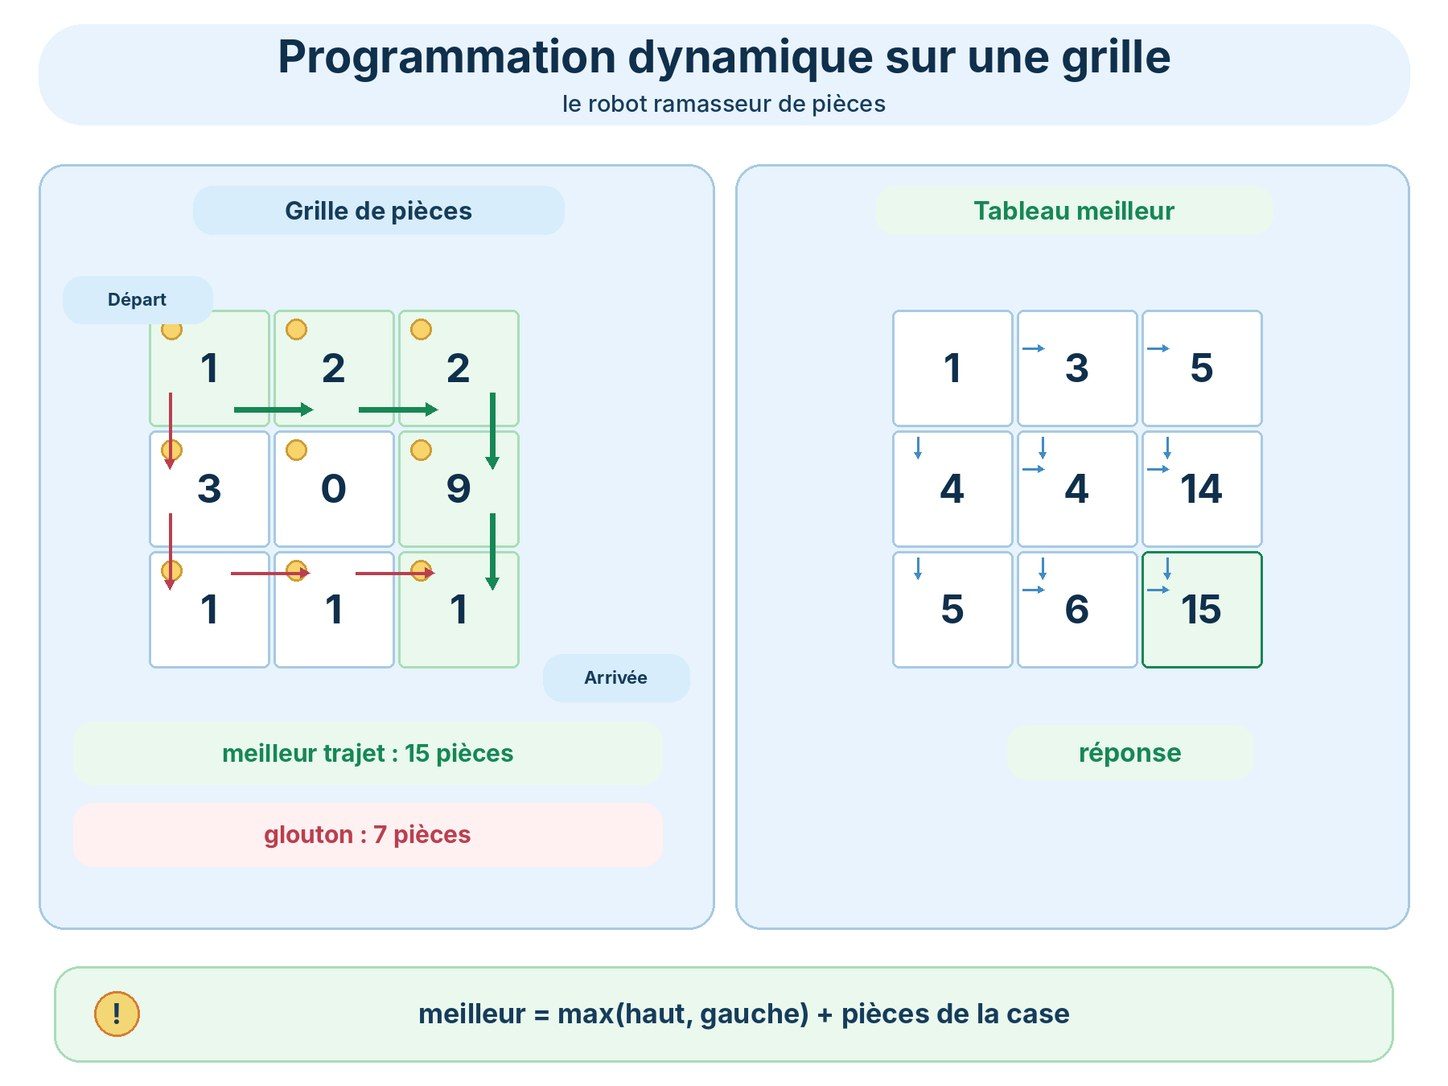

Sur l'image, à gauche, la grille de pièces avec deux trajets : en pointillés rouges, celui du glouton (7 pièces) ; en vert, le meilleur trajet (15 pièces). À droite, le tableau `meilleur`, rempli ligne par ligne : chaque case vaut la plus grande de ses deux cases « d'arrivée » (en haut, à gauche), plus les pièces de la case. La case en bas à droite donne la réponse : 15.

In [ ]:
def max_pieces(grille, afficher=False):
    lignes, colonnes = len(grille), len(grille[0])
    # meilleur[i][j] = le plus de pièces possible en ARRIVANT sur la case (i, j)
    meilleur = [[0] * colonnes for _ in range(lignes)]      # et surtout pas [[0] * colonnes] * lignes (thème 2) !
    for i in range(lignes):
        for j in range(colonnes):
            if i == 0 and j == 0:
                avant = 0                                   # le départ : rien avant
            elif i == 0:
                avant = meilleur[i][j - 1]                  # 1re ligne : on vient forcément de la gauche
            elif j == 0:
                avant = meilleur[i - 1][j]                  # 1re colonne : on vient forcément d'en haut
            else:
                avant = max(meilleur[i - 1][j], meilleur[i][j - 1])   # la meilleure des deux arrivées
            meilleur[i][j] = avant + grille[i][j]
    if afficher:
        for ligne in meilleur:
            print(" ".join(f"{v:3}" for v in ligne))
    return meilleur[lignes - 1][colonnes - 1]

grille = [
    [1, 2, 2],
    [3, 0, 9],
    [1, 1, 1],
]
print("réponse :", max_pieces(grille, afficher=True))   # 15

**Trace à la main** du tableau `meilleur` (chaque case = max(haut, gauche) + pièces de la case) :
```
        j = 0        j = 1               j = 2
i = 0   1            1 + 2 = 3           3 + 2 = 5
i = 1   1 + 3 = 4    max(3, 4) + 0 = 4   max(5, 4) + 9 = 14
i = 2   4 + 1 = 5    max(4, 5) + 1 = 6   max(14, 6) + 1 = 15
```
**Complexité** : un calcul en O(1) par case → **O(lignes × colonnes)** : 400 calculs pour une grille 20 × 20, au lieu de 35 milliards de chemins.

### La revanche des pièces {1, 3, 4}
Au thème 7, le glouton rendait 6 avec 3 pièces (4 + 1 + 1) au lieu de 2 (3 + 3). La programmation dynamique, elle, ne se trompe pas :
1. `mini[s]` = le plus petit nombre de pièces pour payer **exactement** `s` ;
2. dernier choix : la **dernière pièce** donnée, `p` → `mini[s] = mini[s - p] + 1`, avec la meilleure pièce `p` ;
3. départ : `mini[0] = 0` (payer 0, c'est ne rien donner) ;
4. ordre : `s` croissant.

In [ ]:
def minimum_pieces_dp(montant, pieces):
    INFINI = float("inf")                       # « impossible, pour l'instant »
    mini = [0] + [INFINI] * montant             # mini[s] = le moins de pièces pour payer exactement s
    for s in range(1, montant + 1):
        for p in pieces:                        # on essaie chaque pièce comme DERNIÈRE pièce donnée
            if p <= s and mini[s - p] + 1 < mini[s]:
                mini[s] = mini[s - p] + 1
    return mini[montant] if mini[montant] != INFINI else -1   # -1 : montant impossible à payer

print(minimum_pieces_dp(6, [1, 3, 4]))     # 2 (3 + 3)
print(minimum_pieces_dp(7, [2, 4]))        # -1 : impossible avec des pièces paires

**Trace à la main** (pièces 1, 3 et 4) :

| `s` | 0 | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| `mini[s]` | 0 | 1 (1) | 2 (1+1) | 1 (3) | 1 (4) | 2 (4+1) | 2 (3+3) |

Le glouton ne regarde qu'**un** choix (la plus grosse pièce) ; la programmation dynamique les essaie **tous**, mais ne résout chaque sous-problème qu'une fois. Coût : O(montant × nombre de pièces).

## Partie 2 — Le backtracking (retour en arrière)

### Le problème de départ
> Trois amis, A, B et C, passent un oral l'un après l'autre. Donne **tous** les ordres de passage possibles.
> → ABC, ACB, BAC, BCA, CAB, CBA (6 ordres).

Cette fois, on ne veut ni **compter** les possibilités, ni trouver **la meilleure** : on veut **toutes les lister**.

### Le concept : explorer l'arbre des choix
On construit un ordre **place par place** : on choisit qui passe en 1er, puis qui passe en 2e parmi ceux qui restent, etc. Quand l'ordre est complet, on le note… puis on **revient en arrière** sur le dernier choix pour essayer l'option suivante.

Image mentale : le labyrinthe du thème 5. On avance tant qu'on peut ; au bout d'un couloir, on note ce qu'on a trouvé, on revient au dernier embranchement, et on prend le couloir suivant. Le backtracking est un **DFS sur l'arbre des choix**.

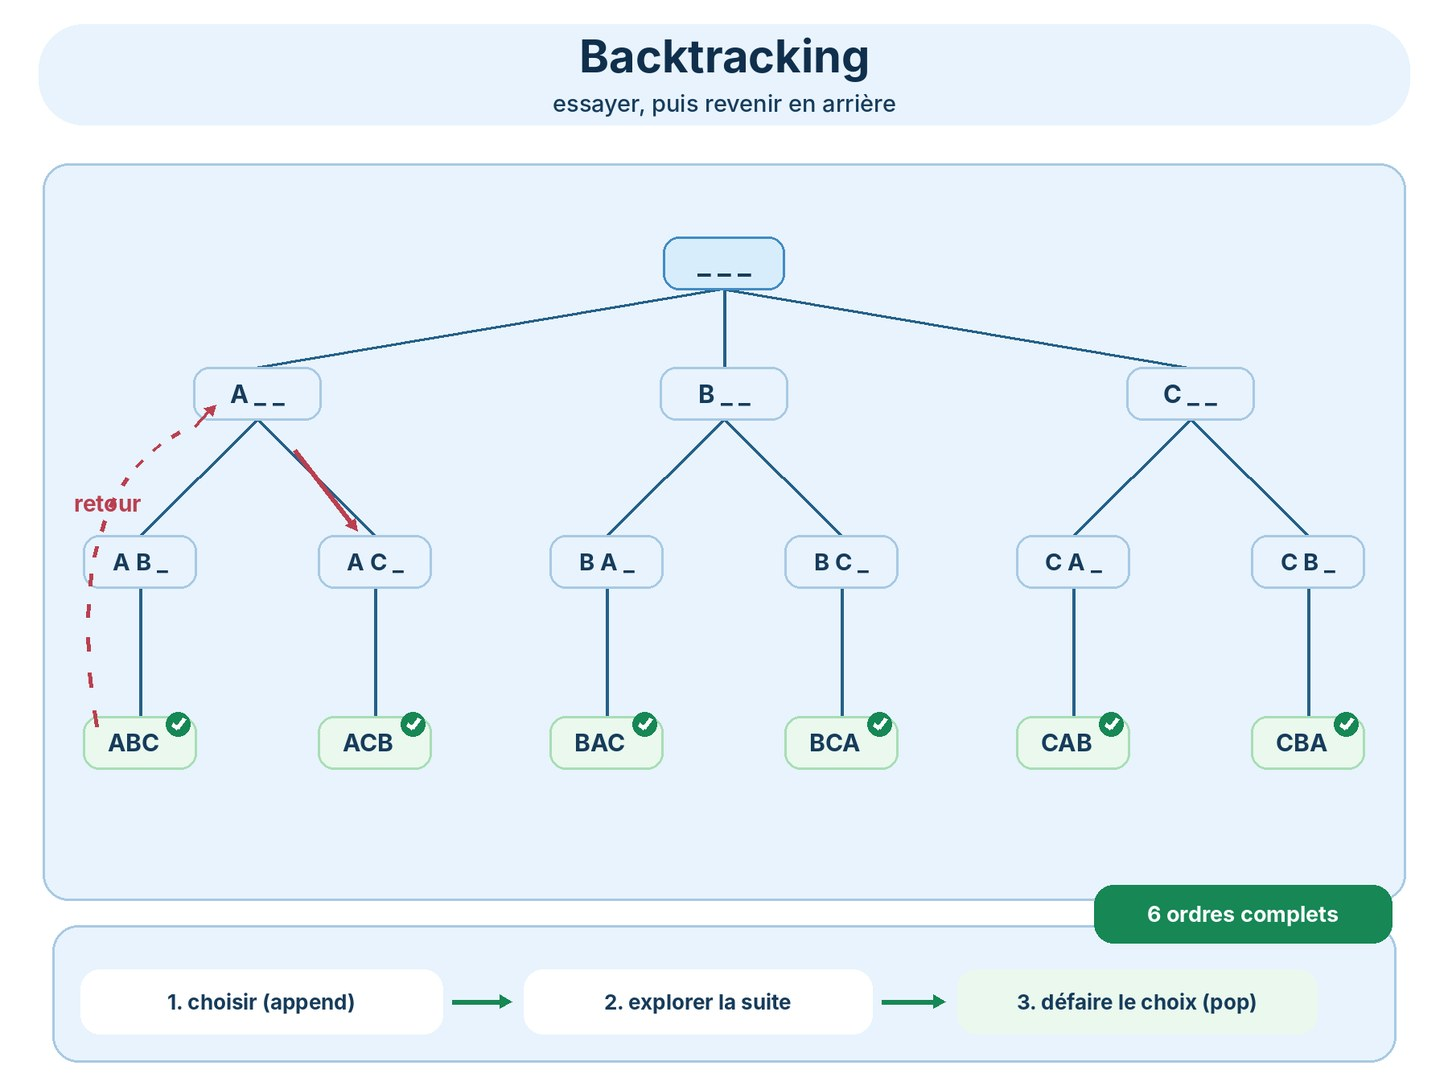

Sur l'image, l'arbre des choix : au départ, un ordre vide ; au 1er niveau, qui passe en premier (A, B ou C) ; au 2e niveau, qui passe en deuxième parmi les deux qui restent ; au 3e niveau, le dernier. Chaque feuille, en vert, est un ordre complet : il y en a 6. Les flèches en pointillés montrent le **retour en arrière** : après ABC, on remonte à « A _ _ » pour essayer C en deuxième position, ce qui donne ACB.

### Le schéma à retenir
```
def construire():
    si la solution est complète :
        enregistrer une COPIE de la solution
        return
    pour chaque choix possible :
        si ce choix est autorisé :
            faire le choix              ← append
            construire()                ← explorer tout ce qui découle de ce choix
            défaire le choix            ← pop : le retour en arrière
```

In [ ]:
def ordres_de_passage(personnes, afficher=False):
    resultat = []
    ordre = []                               # l'ordre en cours de construction

    def construire():
        if len(ordre) == len(personnes):     # tout le monde est placé : un ordre complet
            resultat.append(ordre[:])        # une COPIE, car ordre va encore changer
            if afficher:
                print("    " * len(ordre) + "✅ " + "".join(ordre))
            return
        for p in personnes:
            if p not in ordre:               # chacun ne passe qu'une fois (liste minuscule : ce in est négligeable)
                if afficher:
                    print("    " * len(ordre) + f"essaie {p}")
                ordre.append(p)              # 1. faire le choix
                construire()                 # 2. explorer la suite
                ordre.pop()                  # 3. défaire le choix : retour en arrière

    construire()
    return resultat

print(ordres_de_passage(["A", "B", "C"], afficher=True))

L'indentation de l'affichage dessine l'arbre de l'image, couché sur le côté : chaque décalage correspond à une place de plus dans l'ordre. Après chaque ✅, l'appel récursif se termine, la fonction **remonte**, défait le dernier choix avec `pop()` et essaie la personne suivante.

### Le piège de la copie
Pourquoi `ordre[:]` et pas `ordre` ? Pour la même raison qu'au thème 2 : `resultat.append(ordre)` range **la liste elle-même**, pas son contenu du moment. Comme `ordre` est ensuite vidée par les `pop()`, toutes les « solutions » finissent identiques… et vides :

In [ ]:
def ordres_SANS_COPIE(personnes):
    resultat, ordre = [], []
    def construire():
        if len(ordre) == len(personnes):
            resultat.append(ordre)           # ❌ la MÊME liste, rangée 6 fois
            return
        for p in personnes:
            if p not in ordre:
                ordre.append(p)
                construire()
                ordre.pop()
    construire()
    return resultat

print(ordres_SANS_COPIE(["A", "B", "C"]))    # [[], [], [], [], [], []]

### Élaguer : ne pas explorer les branches sans espoir
Le backtracking devient vraiment intéressant quand il y a une **contrainte** : on peut alors abandonner une branche **dès qu'elle ne peut plus mener à une solution**, sans explorer tout ce qui pousse en dessous. C'est l'**élagage**, comme on coupe une branche morte.

> Parmi des nombres **positifs**, trouve tous les groupes dont la somme vaut exactement `cible`.
> `[2, 3, 5, 7]`, cible 10 → `[2, 3, 5]` et `[3, 7]`.

Pour chaque nombre, deux choix : le **prendre** ou **ne pas le prendre**. Et si la somme déjà prise dépasse la cible, inutile de continuer : les nombres étant positifs, en ajouter d'autres ne ferait qu'aggraver les choses.

In [ ]:
def sommes_cibles(nombres, cible):
    resultat = []
    choisis = []

    def explorer(i, reste):                 # i : prochain nombre à décider ; reste : ce qui manque pour la cible
        if reste == 0:
            resultat.append(choisis[:])     # cible atteinte : une solution (une copie !)
            return
        if reste < 0 or i == len(nombres):
            return                          # élagage : cible dépassée, ou plus rien à essayer
        choisis.append(nombres[i])          # choix 1 : on PREND nombres[i]
        explorer(i + 1, reste - nombres[i])
        choisis.pop()                       # retour en arrière
        explorer(i + 1, reste)              # choix 2 : on ne le prend PAS

    explorer(0, cible)
    return resultat

print(sommes_cibles([2, 3, 5, 7], 10))   # [[2, 3, 5], [3, 7]]

Combien de travail l'élagage évite-t-il ? Comptons les appels, avec et sans la condition `reste < 0`, sur les nombres de 1 à 18 et la cible 15.
(`nonlocal` permet à la fonction intérieure de modifier la variable `appels` de la fonction qui l'entoure.)

In [ ]:
def compter_appels(nombres, cible, elaguer):
    appels = 0
    def explorer(i, reste):
        nonlocal appels
        appels += 1
        if reste == 0:
            return
        if (elaguer and reste < 0) or i == len(nombres):
            return
        explorer(i + 1, reste - nombres[i])
        explorer(i + 1, reste)
    explorer(0, cible)
    return appels

nombres = list(range(1, 19))     # 1, 2, …, 18
print("sans élagage :", compter_appels(nombres, 15, elaguer=False), "appels")
print("avec élagage :", compter_appels(nombres, 15, elaguer=True), "appels")

**Le prix du backtracking** : le nombre de possibilités explose avec `n`.

| `n` | sous-ensembles : 2ⁿ | ordres : n! |
|---|---|---|
| 5 | 32 | 120 |
| 10 | 1 024 | 3 628 800 |
| 20 | 1 048 576 | 2 432 902 008 176 640 000 |

Le backtracking est donc réservé aux **petites** entrées (`n` jusqu'à 10 ou 20 selon les cas) : lis les contraintes (thème 0). L'élagage aide beaucoup, mais ne change pas cette règle.

(Sans contrainte particulière, le module `itertools` fournit `permutations` et `combinations` tout faits. Dès qu'il y a une contrainte, il faut savoir écrire le backtracking soi-même.)

### Programmation dynamique ou backtracking ?
| L'énoncé demande… | Outil |
|---|---|
| **combien** de façons, de chemins, de combinaisons | programmation dynamique |
| le **meilleur** résultat (maximum, minimum) avec des choix successifs | programmation dynamique (ou un glouton, s'il est prouvé juste) |
| la **liste de toutes** les solutions | backtracking |
| `n` grand (100, 1 000, 10 000…) | programmation dynamique : le backtracking serait bien trop lent |

Exemple : dans une grille 20 × 20, **compter** les chemins est immédiat (400 cases à remplir) ; les **lister** tous est impossible (plus de 35 milliards).

## Quand y penser ?
- « de combien de façons », « nombre de chemins », « nombre de combinaisons » → **programmation dynamique** ;
- « le maximum / minimum qu'on peut obtenir » avec des choix qui s'enchaînent (prendre ou non, aller à droite ou en bas…) → **programmation dynamique** ;
- une solution récursive qui recalcule les mêmes valeurs → **mémoïser** avec `@cache` ;
- un glouton qui a un contre-exemple → **programmation dynamique** ;
- « toutes les combinaisons / permutations / tous les sous-ensembles », « génère tous les… », avec `n` petit → **backtracking**.

## Les pièges
- Oublier les cas de départ (`facons[0] = 1`) → tout le tableau reste à 0.
- Remplir dans le mauvais ordre : une case utilisée avant d'avoir été calculée.
- Créer un tableau 2D avec `[[0] * c] * l` → des lignes partagées (thème 2).
- Une récursion de plus de 1 000 niveaux environ → `RecursionError` : passer au tableau.
- Backtracking : `resultat.append(solution)` au lieu de `solution[:]` → une liste de listes vides.
- Oublier de défaire le choix (`pop`) après l'appel récursif.
- Lancer un backtracking sur `n = 40` : 2⁴⁰, c'est plus de mille milliards de possibilités.

## À toi de jouer — la meilleure portion
> Écris `somme_max_portion(nombres)` qui renvoie la plus grande somme d'une portion **contiguë** et **non vide** de la liste (la liste contient au moins un élément).
> `somme_max_portion([-2, 1, -3, 4, -1, 2, 1, -5, 4])` → `6` (la portion `[4, -1, 2, 1]`).

Contrainte : jusqu'à 100 000 éléments. Tester toutes les portions (O(n²)) est trop lent.

**Indice** : applique la méthode en 4 questions, avec une case par position. `meilleure_ici` = la plus grande somme d'une portion qui **se termine exactement** sur l'élément courant `x`. Dernier choix : soit cette portion est `x` **tout seul**, soit elle **prolonge** la meilleure portion qui se terminait juste avant. La réponse est le plus grand `meilleure_ici` rencontré.

In [ ]:
def somme_max_portion(nombres):
    # À toi de jouer !
    pass

verifier(somme_max_portion, [
    (([-2, 1, -3, 4, -1, 2, 1, -5, 4],), 6),
    (([5],), 5),
    (([-3, -1, -2],), -1),          # que des négatifs : la portion non vide la moins mauvaise
    (([1, 2, 3],), 6),              # toute la liste
    (([2, -1, 2],), 3),             # traverser un négatif peut valoir le coup
    (([-1, 4, -10, 3, 3],), 6),     # mieux vaut repartir de zéro après le -10
])

<details>
<summary><b>Voir la solution</b> (essaie vraiment d'abord !)</summary>

```python
def somme_max_portion(nombres):
    meilleure_ici = nombres[0]      # meilleure portion qui se termine sur l'élément courant
    meilleure = nombres[0]          # meilleure portion vue jusqu'ici, où qu'elle se termine
    for x in nombres[1:]:
        meilleure_ici = max(x, meilleure_ici + x)   # x tout seul, ou x qui prolonge la portion précédente
        meilleure = max(meilleure, meilleure_ici)
    return meilleure

# Un seul passage : O(n). Comme pour l'escalier, chaque case n'utilise que la précédente :
# une variable suffit au lieu d'un tableau. (Cet algorithme porte le nom de Kadane.)
```

</details>

---

**Suite :** après la série 8, les [examens blancs](exercices/examen_blanc_A.ipynb) ➡ · [Retour au sommaire](00_sommaire.ipynb)

**S'entraîner :** [Série 8 — Récursivité, programmation dynamique et backtracking](exercices/serie8_dp_backtracking.ipynb) (7 exercices avec tests automatiques)